---
title: Forecast Related Time Series with TabPFN 3.5
description: Build date, Fourier, and autoregressive features, then compare individual, family, store, and global forecasting contexts.
icon: chart-line
cookbookTags:
  - time-series
  - regression
authors:
  - name: Eliott Kalfon
    linkedin: https://www.linkedin.com/in/eliott-kalfon/
---

A grocery retailer needs tomorrow's replenishment plan for many stores and product families. Promotions are planned in advance, but sales are only observed through today. We will forecast sales with **TabPFN 3.5**, first following two series visually, then sharing history across **48 series**.

We build ordinary date features before adding Fourier terms, introduce a two-day-ahead autoregressive forecast, and extend it to a separate model for each of 14 horizons. Finally, we compare one context per series, one per product family, one per store, and one global context. The results determine whether pooling improves accuracy, runtime, or both.

## Setup

In [ ]:
%pip install -q --upgrade "tabpfn>=9.0" pandas matplotlib huggingface-hub


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from huggingface_hub import hf_hub_download

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 150)
pd.set_option("display.precision", 3)
COLORS = {"Basic dates": "#8C8C8C", "Fourier": "#E88B32", "Direct AR": "#2878B5"}


## Load a panel of related series
We use [Favorita Store Sales](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data), accessed through a [public mirror](https://huggingface.co/datasets/t4tiana/store-sales-time-series-forecasting). The snapshot is fixed for reproducibility. Sales are quantities, not revenue; some families include quantities measured by weight.

The subset is fixed before evaluating forecasts: stores 1–12 and BEVERAGES, BREAD/BAKERY, CLEANING, and GROCERY I. These **48 store–family series** form four groups of 12. We retain roughly two years of training history plus earlier observations for lag construction. This is a teaching subset, not a benchmark of the full competition.

Holiday features respect city/state/national scope and transferred dates. Future promotion counts are treated as plans known at the origin, matching the competition's provision of future promotions; the historical file does not preserve plan revisions. Realized future oil prices and transaction counts are excluded.


In [2]:
STORES = list(range(1, 13))
FAMILIES = ["BEVERAGES", "BREAD/BAKERY", "CLEANING", "GROCERY I"]
DATASET = "t4tiana/store-sales-time-series-forecasting"
REVISION = "1ac138dfdfafc520bc29831e73373954b1b7bc05"
panel_path = Path("favorita_daily.csv")

if not panel_path.exists():
    def source_file(name):
        return hf_hub_download(DATASET, name, repo_type="dataset", revision=REVISION)

    chunks = pd.read_csv(source_file("train.csv"), parse_dates=["date"], chunksize=250_000)
    selected = []
    for chunk in chunks:
        keep = (chunk.store_nbr.isin(STORES) & chunk.family.isin(FAMILIES)
                & chunk.date.ge("2015-04-01"))
        selected.append(chunk.loc[keep, ["date", "store_nbr", "family", "sales", "onpromotion"]])
    panel = pd.concat(selected, ignore_index=True)
    stores = pd.read_csv(source_file("stores.csv"))
    panel = panel.merge(stores[["store_nbr", "city", "state", "type", "cluster"]],
                        on="store_nbr", validate="many_to_one")
    holidays = pd.read_csv(source_file("holidays_events.csv"), parse_dates=["date"])
    holidays = holidays.loc[~holidays.transferred & holidays.type.isin(
        ["Holiday", "Additional", "Bridge", "Transfer"])]
    panel["is_holiday"] = 0
    for holiday in holidays.itertuples():
        applies = panel.date.eq(holiday.date)
        if holiday.locale == "Regional":
            applies &= panel.state.eq(holiday.locale_name)
        elif holiday.locale == "Local":
            applies &= panel.city.eq(holiday.locale_name)
        panel.loc[applies, "is_holiday"] = 1
    panel["series_id"] = panel.store_nbr.astype(str) + " / " + panel.family
    panel.sort_values(["series_id", "date"]).to_csv(panel_path, index=False)

panel = pd.read_csv(panel_path, parse_dates=["date"])
assert not panel.duplicated(["series_id", "date"]).any()
assert panel.series_id.nunique() == 48
print(f"{panel.series_id.nunique()} series, {panel.family.nunique()} groups, {len(panel):,} observations")
display(panel.loc[panel.series_id.isin(["5 / CLEANING", "9 / GROCERY I"]),
                  ["date", "series_id", "sales", "onpromotion", "is_holiday"]]
        .groupby("series_id", sort=False).head(3))


48 series, 4 groups, 41,568 observations


,date,series_id,sales,onpromotion,is_holiday
25980,2015-04-01,5 / CLEANING,1369.000,3,0
25981,2015-04-02,5 / CLEANING,1116.000,5,0
25982,2015-04-03,5 / CLEANING,787.000,3,1
40702,2015-04-01,9 / GROCERY I,7278.159,4,0
40703,2015-04-02,9 / GROCERY I,6986.778,4,0
40704,2015-04-03,9 / GROCERY I,6254.095,3,1


## Two series and a forecast origin
We pick two series as an example. At an origin $t$, sales through $t$ are observed. Dates, calendar features, and planned promotions for $t+1$ through $t+14$ are available. Sales in that window are labels used only for scoring.


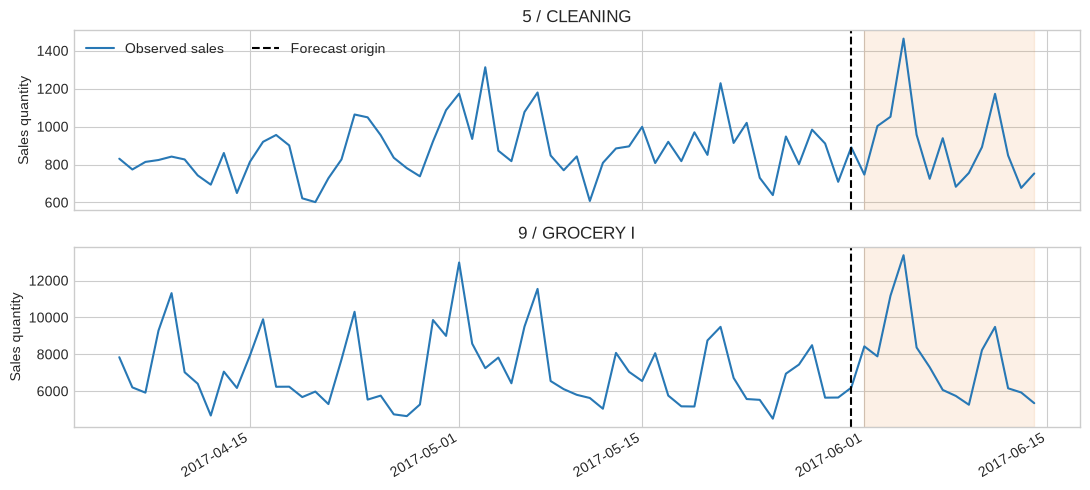

In [3]:
H = 14
HISTORY_DAYS = 730
DEMO_ORIGIN = pd.Timestamp("2017-05-31")
TEST_ORIGINS = pd.to_datetime(["2017-06-30", "2017-07-14", "2017-07-28"])
EXAMPLES = ["5 / CLEANING", "9 / GROCERY I"]
demo = panel.loc[panel.series_id.isin(EXAMPLES)].copy()

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, series in zip(axes, EXAMPLES):
    view = demo.loc[demo.series_id.eq(series) & demo.date.between(
        DEMO_ORIGIN - pd.Timedelta(days=56), DEMO_ORIGIN + pd.Timedelta(days=H))]
    ax.plot(view.date, view.sales, color="#2878B5", label="Observed sales")
    ax.axvline(DEMO_ORIGIN, color="black", linestyle="--", label="Forecast origin")
    ax.axvspan(DEMO_ORIGIN + pd.Timedelta(days=1), view.date.max(), alpha=.12, color="#E88B32")
    ax.set(title=series, ylabel="Sales quantity")
axes[0].legend(loc="upper left", ncol=2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## Start with ordinary date features
A date becomes **year, month, day of month, weekday, and a time index**. Add the same known covariates and static identifiers that we will keep in later models.

In [4]:
IDENTIFIERS = ["store_nbr", "family", "city", "state", "type", "cluster"]
KNOWN = ["onpromotion", "is_holiday"]
BASIC = ["year", "month", "day", "weekday", "time_index"]

def date_features(data):
    result = data.copy()
    result["year"] = result.date.dt.year
    result["month"] = result.date.dt.month
    result["day"] = result.date.dt.day
    result["weekday"] = result.date.dt.dayofweek
    result["time_index"] = (result.date - pd.Timestamp("2015-01-01")).dt.days
    for column in IDENTIFIERS:
        result[column] = result[column].astype(str)
    return result

features = date_features(panel)
display(features.loc[features.series_id.isin(EXAMPLES) & features.date.between(
    DEMO_ORIGIN - pd.Timedelta(days=1), DEMO_ORIGIN + pd.Timedelta(days=2)),
    ["series_id", "date", "weekday", "month", "day", "onpromotion", "sales"]]
    .sort_values(["date", "series_id"]))


,series_id,date,weekday,month,day,onpromotion,sales
26768,5 / CLEANING,2017-05-30,1,5,30,30,709.000
41490,9 / GROCERY I,2017-05-30,1,5,30,62,5655.773
26769,5 / CLEANING,2017-05-31,2,5,31,37,891.000
41491,9 / GROCERY I,2017-05-31,2,5,31,61,6190.070
26770,5 / CLEANING,2017-06-01,3,6,1,3,747.000
41492,9 / GROCERY I,2017-06-01,3,6,1,38,8430.211
26771,5 / CLEANING,2017-06-02,4,6,2,9,1003.000
41493,9 / GROCERY I,2017-06-02,4,6,2,72,7889.789


In [5]:
import gc
import importlib.metadata
import time
import torch
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion

assert torch.cuda.is_available(), "Select a GPU runtime to run this cookbook."
print(f"TabPFN {importlib.metadata.version('tabpfn')} | model v3.5 | {torch.cuda.get_device_name()}")

def predict_context(train, query, columns):
    model = TabPFNRegressor.create_default_for_version(
        ModelVersion.V3_5, device="cuda", random_state=42)
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    model.fit(train[columns], train.sales)
    prediction = np.maximum(0, model.predict(query[columns]))
    torch.cuda.synchronize()
    stats = {"seconds": time.perf_counter() - started,
             "peak_gpu_gb": torch.cuda.max_memory_allocated() / 1e9,
             "train_rows": len(train), "query_rows": len(query),
             "ensemble_members": int(model.n_estimators_)}
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return prediction, stats

# Warm the model/device once; the separate warm-up is excluded from timings.
warm = features.loc[features.series_id.eq(EXAMPLES[0]) & features.date.le(DEMO_ORIGIN)].tail(130)
_ = predict_context(warm.iloc[:-2], warm.iloc[-2:], IDENTIFIERS + KNOWN + BASIC)


TabPFN 9.1.0 | model v3.5 | NVIDIA L4


,series_id,date,sales,prediction
0,5 / CLEANING,2017-06-01,747.000,747.468
1,5 / CLEANING,2017-06-02,1003.000,948.884
2,5 / CLEANING,2017-06-03,1052.000,1035.255
14,9 / GROCERY I,2017-06-01,8430.211,8148.824
15,9 / GROCERY I,2017-06-02,7889.789,7344.195
16,9 / GROCERY I,2017-06-03,11174.906,10616.280


Basic-date MAE: 251.02


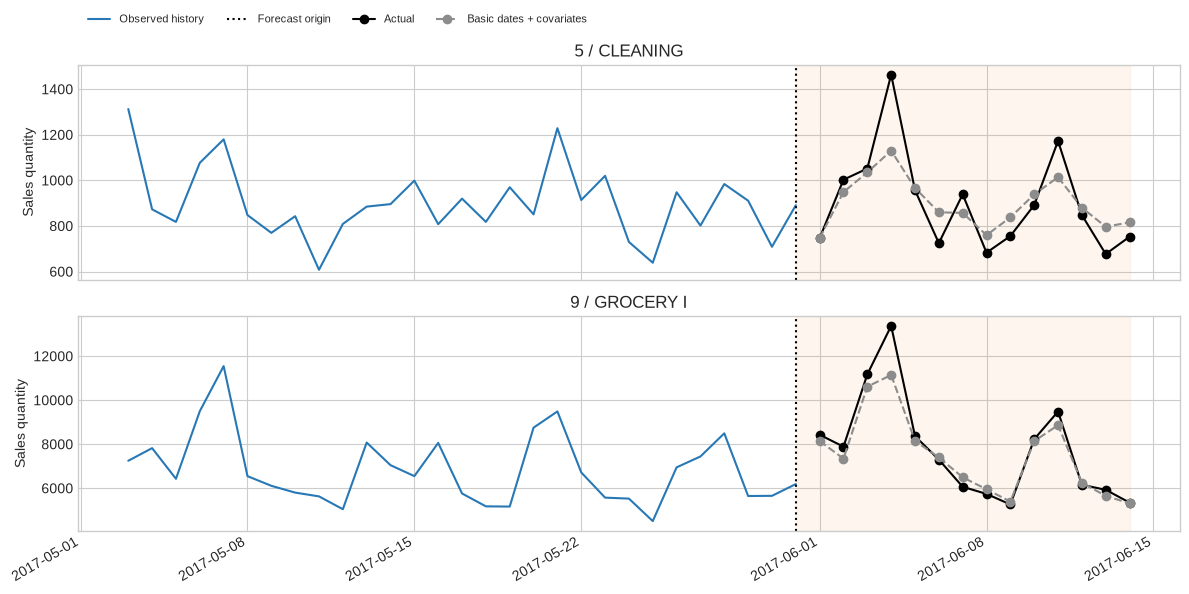

In [7]:
def calendar_forecast(data, origin, columns, strategy="Per series"):
    train = data.loc[data.date.between(origin - pd.Timedelta(days=HISTORY_DAYS - 1), origin)]
    query = data.loc[data.date.between(origin + pd.Timedelta(days=1), origin + pd.Timedelta(days=H))]
    return forecast_contexts(train, query, columns, strategy, origin)

def forecast_contexts(train, query, columns, strategy, origin):
    group_column = {"Per series": "series_id", "By family": "family", "By store": "store_nbr", "Global": None}[strategy]
    groups = [("all", query)] if group_column is None else query.groupby(group_column, sort=True)
    predictions, timings = [], []
    for name, target_rows in groups:
        context = train if group_column is None else train.loc[train[group_column].eq(name)]
        values, stats = predict_context(context, target_rows, columns)
        result = target_rows[["series_id", "family", "date", "sales"]].copy()
        result["prediction"] = values
        result["origin"] = origin
        result["horizon"] = (result.date - origin).dt.days
        result["strategy"] = strategy
        predictions.append(result)
        timings.append(stats | {"origin": origin, "strategy": strategy, "context": str(name)})
    return pd.concat(predictions, ignore_index=True), pd.DataFrame(timings)

demo_features = features.loc[features.series_id.isin(EXAMPLES)]
basic_predictions, basic_timing = calendar_forecast(
    demo_features, DEMO_ORIGIN, IDENTIFIERS + KNOWN + BASIC)
basic_predictions["method"] = "Basic dates"
display(basic_predictions[["series_id", "date", "sales", "prediction"]].groupby("series_id").head(3))
print("Basic-date MAE:", round(abs(basic_predictions.sales - basic_predictions.prediction).mean(), 2))
def plot_history(ax, series):
    history = demo.loc[demo.series_id.eq(series) & demo.date.between(
        DEMO_ORIGIN - pd.Timedelta(days=28), DEMO_ORIGIN)]
    ax.plot(history.date, history.sales, "-", color="#2878B5", label="Observed history")
    ax.axvline(DEMO_ORIGIN, color="black", linestyle=":", label="Forecast origin")
    ax.axvspan(DEMO_ORIGIN, DEMO_ORIGIN + pd.Timedelta(days=H), color="#E88B32", alpha=.08)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, series in zip(axes, EXAMPLES):
    plot_history(ax, series)
    rows = basic_predictions.loc[basic_predictions.series_id.eq(series)]
    ax.plot(rows.date, rows.sales, "o-", color="black", label="Actual")
    ax.plot(rows.date, rows.prediction, "o--", color=COLORS["Basic dates"], label="Basic dates + covariates")
    ax.set(title=series, ylabel="Sales quantity")
axes[0].legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.14), fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## Add Fourier terms to describe repeating seasons
For each period $P$, add $\sin(2\pi k d/P)$ and $\cos(2\pi k d/P)$. We use two harmonics for the weekly and annual cycles: **eight extra columns**. These depend only on the target date and remain available at any forecast horizon.

Everything else stays the same, including promotions, training dates, model settings, and held-out targets.


,series_id,date,weekday,week_sin_1,week_cos_1,year_sin_1,year_cos_1,onpromotion
26769,5 / CLEANING,2017-05-31,2,-7.818e-01,0.623,0.525,-0.851,37
41491,9 / GROCERY I,2017-05-31,2,-7.818e-01,0.623,0.525,-0.851,61
26770,5 / CLEANING,2017-06-01,3,-1.019e-13,1.000,0.510,-0.860,3
41492,9 / GROCERY I,2017-06-01,3,-1.019e-13,1.000,0.510,-0.860,38
26771,5 / CLEANING,2017-06-02,4,7.818e-01,0.623,0.495,-0.869,9
41493,9 / GROCERY I,2017-06-02,4,7.818e-01,0.623,0.495,-0.869,72


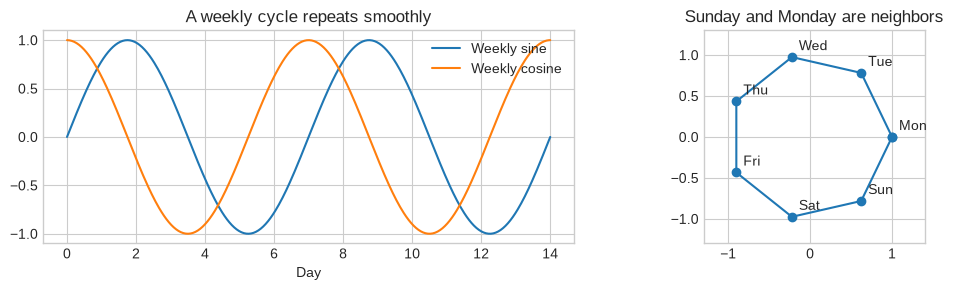

In [8]:
FOURIER = []
for name, period in [("week", 7), ("year", 365.25)]:
    for harmonic in [1, 2]:
        angle = 2 * np.pi * harmonic * features.time_index / period
        for function, values in [("sin", np.sin(angle)), ("cos", np.cos(angle))]:
            column = f"{name}_{function}_{harmonic}"
            features[column] = values
            FOURIER.append(column)

example_rows = features.loc[features.series_id.isin(EXAMPLES) & features.date.between(
    DEMO_ORIGIN, DEMO_ORIGIN + pd.Timedelta(days=2))]
display(example_rows[["series_id", "date", "weekday", "week_sin_1", "week_cos_1",
                      "year_sin_1", "year_cos_1", "onpromotion"]]
        .sort_values(["date", "series_id"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
days = np.linspace(0, 14, 400)
axes[0].plot(days, np.sin(2 * np.pi * days / 7), label="Weekly sine")
axes[0].plot(days, np.cos(2 * np.pi * days / 7), label="Weekly cosine")
axes[0].set(xlabel="Day", title="A weekly cycle repeats smoothly")
axes[0].legend()
weekdays = np.arange(7)
x, y = np.cos(2 * np.pi * weekdays / 7), np.sin(2 * np.pi * weekdays / 7)
axes[1].plot(np.r_[x, x[0]], np.r_[y, y[0]], "o-")
for day, a, b in zip(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], x, y):
    axes[1].annotate(day, (a, b), xytext=(5, 5), textcoords="offset points")
axes[1].set(xlim=(-1.3, 1.4), ylim=(-1.3, 1.3), title="Sunday and Monday are neighbors")
axes[1].set_aspect("equal")
fig.tight_layout()
plt.show()


method,Basic dates,Fourier
series_id,,
5 / CLEANING,86.465,74.851
9 / GROCERY I,415.577,359.804


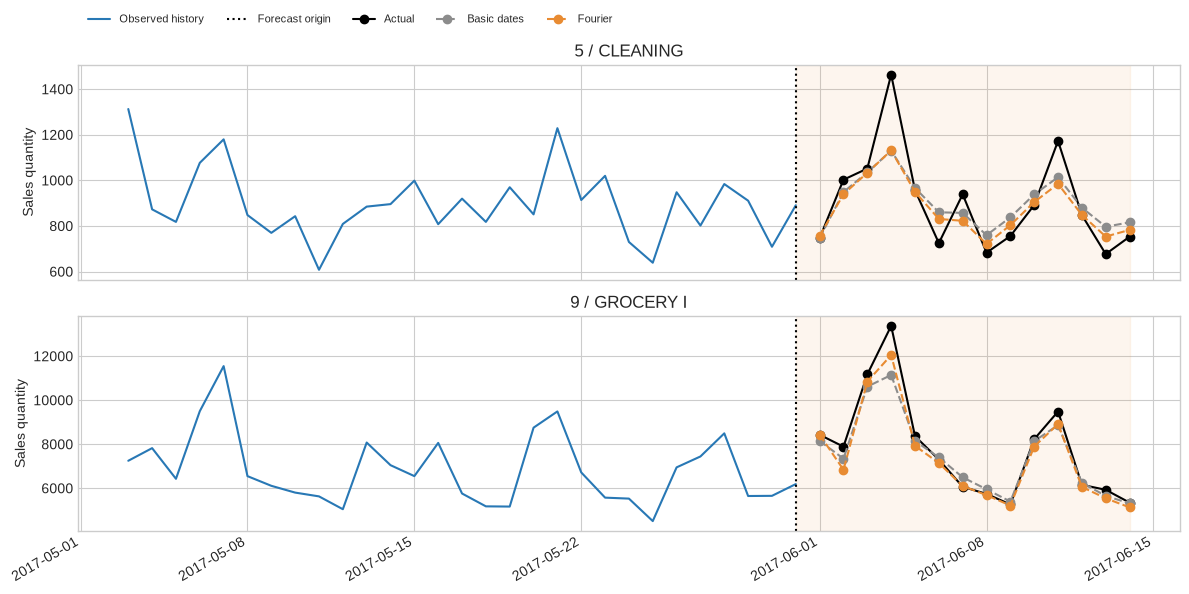

In [9]:
CALENDAR_COLUMNS = IDENTIFIERS + KNOWN + BASIC + FOURIER
demo_features = features.loc[features.series_id.isin(EXAMPLES)]
fourier_predictions, fourier_timing = calendar_forecast(demo_features, DEMO_ORIGIN, CALENDAR_COLUMNS)
fourier_predictions["method"] = "Fourier"
date_comparison = pd.concat([basic_predictions, fourier_predictions], ignore_index=True)
date_comparison["absolute_error"] = abs(date_comparison.sales - date_comparison.prediction)
display(date_comparison.groupby(["series_id", "method"]).absolute_error.mean().unstack())

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, series in zip(axes, EXAMPLES):
    plot_history(ax, series)
    rows = date_comparison.loc[date_comparison.series_id.eq(series)]
    actual = rows.drop_duplicates("date")
    ax.plot(actual.date, actual.sales, "o-", color="black", label="Actual")
    for method, group in rows.groupby("method"):
        ax.plot(group.date, group.prediction, "o--", color=COLORS[method], label=method)
    ax.set(title=series, ylabel="Sales quantity")
axes[0].legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.14), fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()



Adding Fourier terms reduces MAE for both illustrated series. Some peaks remain underestimated.


## Add observed history to predict two days ahead
A supervised row now has two dates: **origin** and **target date**. At origin $t$, `last_sales` is $y_t$; `sales_7d_ago` is $y_{t-7}$; the trailing means end at $t$. Promotions, Fourier terms, and calendar features belong to the **target date $t+2$**.

The training label is $y_{t+2}$. A training row is eligible only when its label date is at or before the current forecast cutoff.

The helper also removes rows with incomplete sales history from both training data and forecast queries. All 48 series have the required history at the evaluation origins used here, but a series with incomplete recent history would be omitted by this helper. When adapting the example, check that every requested series and horizon has a prediction, and choose an explicit missing-history policy before using the forecasts.

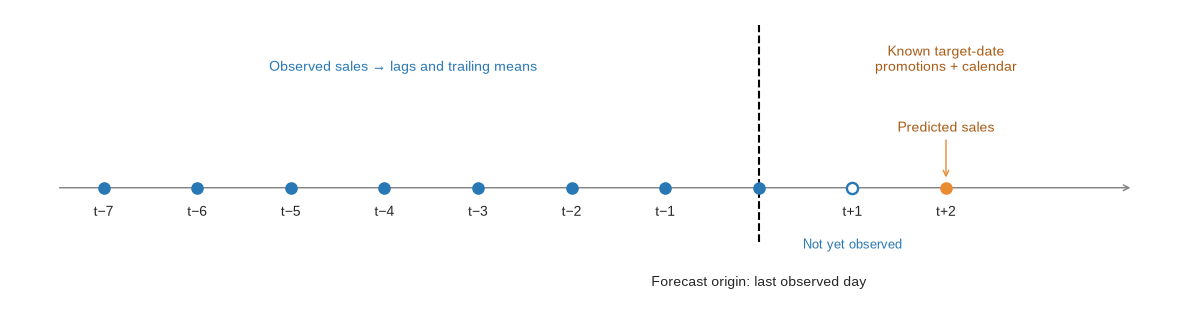

In [10]:
# History stays on the observed side of the forecast origin.
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.set_xlim(-8, 4.5)
ax.set_ylim(-1.2, 1.9)
ax.axvline(0, ymin=.2, ymax=.95, color="black", linestyle="--")
ax.annotate("", xy=(4, 0), xytext=(-7.5, 0), arrowprops={"arrowstyle": "->", "color": "gray"})
for day in range(-7, 1):
    ax.scatter(day, 0, color="#2878B5", s=65, zorder=3)
    if day < 0:
        ax.text(day, -.3, f"t−{abs(day)}", ha="center")
ax.scatter(1, 0, facecolors="white", edgecolors="#2878B5", linewidths=1.7, s=65, zorder=3)
ax.text(1, -.3, "t+1", ha="center")
ax.text(1, -.65, "Not yet observed", ha="center", fontsize=9, color="#2878B5")
ax.scatter(2, 0, color="#E88B32", s=65, zorder=3)
ax.text(2, -.3, "t+2", ha="center")
ax.annotate("Predicted sales", xy=(2, .08), xytext=(2, .6), ha="center",
            color="#A85B15", arrowprops={"arrowstyle": "->", "color": "#E88B32"})
ax.text(-3.8, 1.25, "Observed sales → lags and trailing means", ha="center", color="#2878B5")
ax.text(2, 1.25, "Known target-date\npromotions + calendar", ha="center", color="#A85B15")
ax.text(0, -1.05, "Forecast origin: last observed day", ha="center")
ax.axis("off")
fig.tight_layout()
plt.show()


In [11]:
AR_COLUMNS = ["last_sales", "sales_1d_ago", "sales_7d_ago", "sales_14d_ago", "mean_7d", "mean_28d"]

# Reindex each series to daily dates before lagging: missing days are not zero sales.
calendar = pd.date_range(features.date.min(), features.date.max(), freq="D")
wide_sales = panel.pivot(index="date", columns="series_id", values="sales").reindex(calendar)
lag_tables = {"last_sales": wide_sales, "sales_1d_ago": wide_sales.shift(1),
              "sales_7d_ago": wide_sales.shift(7), "sales_14d_ago": wide_sales.shift(14),
              "mean_7d": wide_sales.rolling(7, min_periods=7).mean(),
              "mean_28d": wide_sales.rolling(28, min_periods=28).mean()}
history = pd.concat({name: table.rename_axis(index="origin", columns="series_id").stack()
                     for name, table in lag_tables.items()}, axis=1).reset_index()

def horizon_rows(data, h):
    targets = data.copy()
    targets["origin"] = targets.date - pd.Timedelta(days=h)
    rows = targets.merge(history, on=["series_id", "origin"], validate="one_to_one")
    return rows.dropna(subset=AR_COLUMNS)

def direct_forecast(data, cutoff, h, strategy="Per series"):
    rows = horizon_rows(data, h)
    train = rows.loc[rows.date.between(cutoff - pd.Timedelta(days=HISTORY_DAYS - 1), cutoff)]
    query = rows.loc[rows.origin.eq(cutoff)]
    assert train.date.max() <= cutoff
    assert query.date.eq(cutoff + pd.Timedelta(days=h)).all()
    return forecast_contexts(train, query, CALENDAR_COLUMNS + AR_COLUMNS, strategy, cutoff)

h2_rows = horizon_rows(demo_features, h=2)
display(h2_rows.loc[h2_rows.origin.between(DEMO_ORIGIN - pd.Timedelta(days=2), DEMO_ORIGIN),
    ["series_id", "origin", "date", "last_sales", "sales_7d_ago", "mean_7d", "onpromotion", "sales"]]
    .sort_values(["origin", "series_id"]))
h2_predictions, h2_timing = direct_forecast(demo_features, DEMO_ORIGIN, h=2)
display(h2_predictions[["series_id", "origin", "date", "horizon", "sales", "prediction"]])


,series_id,origin,date,last_sales,sales_7d_ago,mean_7d,onpromotion,sales
787,5 / CLEANING,2017-05-29,2017-05-31,911.000,914.000,862.000,37,891.000
1651,9 / GROCERY I,2017-05-29,2017-05-31,5648.195,6719.906,6307.104,61,6190.070
788,5 / CLEANING,2017-05-30,2017-06-01,709.000,1020.000,817.571,3,747.000
1652,9 / GROCERY I,2017-05-30,2017-06-01,5655.773,5573.953,6318.792,38,8430.211
789,5 / CLEANING,2017-05-31,2017-06-02,891.000,730.000,840.571,9,1003.000
1653,9 / GROCERY I,2017-05-31,2017-06-02,6190.070,5530.219,6413.057,72,7889.789


,series_id,origin,date,horizon,sales,prediction
0,5 / CLEANING,2017-05-31,2017-06-02,2,1003.000,967.214
1,9 / GROCERY I,2017-05-31,2017-06-02,2,7889.789,7154.654


## Forecast all 14 horizons directly

The two-day-ahead model above is already a **direct forecast**: it maps observed history at origin $t$ and known target-date covariates to sales at $t+2$. We now repeat that construction for every horizon $h=1,\ldots,14$.

The distinction is between **origin-relative** and **target-relative** lags. Sales two days before the origin, $y_{t-2}$, are known for every forecast horizon. A two-day lag relative to the target $t+h$ would instead be $y_{t+h-2}$; for $h=3$, that requires $y_{t+1}$, which is not yet observed. Our features are origin-relative, so the same observed sales history is available for all 14 horizons.

This implementation fits a separate model for each horizon. Historical rows pair history at an origin with the label $h$ days later, and only labels observed by the current cutoff enter training. Query rows share the history through $t$, while their target-date calendar and promotion features change with $h$. No predicted sales are fed into another horizon's history. Separate fits are a modeling choice, not a requirement imposed by lag features; the existing $h=2$ fit is reused.

For our two illustrated series this requires **2 × 14 = 28 fits**, compared with **2 fits** for either calendar-only method.


,series_id,origin,h,date,last_sales,mean_7d,onpromotion,sales
789,5 / CLEANING,2017-05-31,1,2017-06-01,891.00,840.571,3,747.000
789,5 / CLEANING,2017-05-31,2,2017-06-02,891.00,840.571,9,1003.000
789,5 / CLEANING,2017-05-31,14,2017-06-14,891.00,840.571,25,753.000
1654,9 / GROCERY I,2017-05-31,1,2017-06-01,6190.07,6413.057,38,8430.211
1653,9 / GROCERY I,2017-05-31,2,2017-06-02,6190.07,6413.057,72,7889.789
1641,9 / GROCERY I,2017-05-31,14,2017-06-14,6190.07,6413.057,98,5348.805


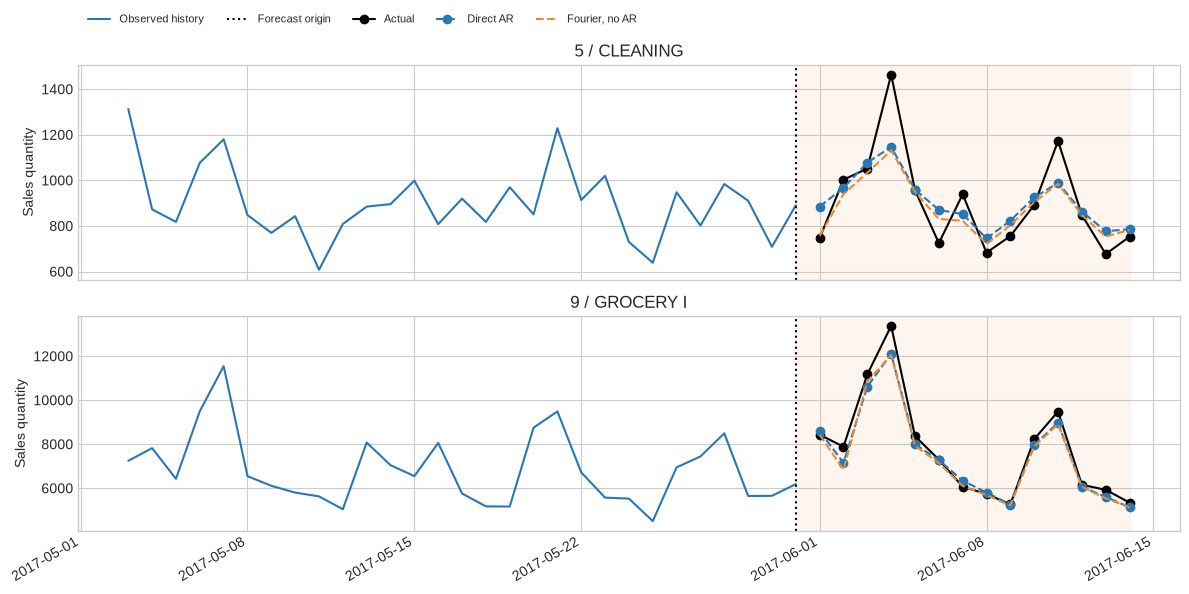

In [12]:
# Show how the same history pairs with three different future dates and labels.
aligned_rows = []
for h in [1, 2, H]:
    rows = horizon_rows(demo_features, h)
    rows = rows.loc[rows.origin.eq(DEMO_ORIGIN)].copy()
    rows["h"] = h
    aligned_rows.append(rows)
display(pd.concat(aligned_rows)[["series_id", "origin", "h", "date", "last_sales",
                                "mean_7d", "onpromotion", "sales"]]
        .sort_values(["series_id", "h"]))

direct_parts, direct_times = [], []
for h in range(1, H + 1):
    # Reuse the identical h=2 calculation rather than fitting it twice.
    prediction, timing = ((h2_predictions, h2_timing) if h == 2
                          else direct_forecast(demo_features, DEMO_ORIGIN, h))
    direct_parts.append(prediction)
    direct_times.append(timing)
direct_predictions = pd.concat(direct_parts, ignore_index=True)
direct_predictions["method"] = "Direct AR"

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, series in zip(axes, EXAMPLES):
    plot_history(ax, series)
    rows = direct_predictions.loc[direct_predictions.series_id.eq(series)].sort_values("date")
    ax.plot(rows.date, rows.sales, "o-", color="black", label="Actual")
    ax.plot(rows.date, rows.prediction, "o--", color=COLORS["Direct AR"], label="Direct AR")
    baseline = fourier_predictions.loc[fourier_predictions.series_id.eq(series)]
    ax.plot(baseline.date, baseline.prediction, "--", color=COLORS["Fourier"], label="Fourier, no AR")
    ax.set(title=series, ylabel="Sales quantity")
axes[0].legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.14), fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## Share the context across related series

Pooling related series lets TabPFN learn from their shared patterns.

This changes which **rows** TabPFN sees, not the forecast target. Each query still predicts one store–family series. Identifiers remain features so a shared model can distinguish stores and families.

* **Per series:** each context contains one store–family history.
* **By family:** each context contains 12 stores selling the same family.
* **By store:** each context contains the four families sold at one store.
* **Global:** one context contains all 48 series.

Family and store are two different ways to group the same leaves: a store–family series belongs to both. This is pooling, not aggregation or reconciliation. Summing leaf predictions would give coherent totals, but we evaluate the individual series here.


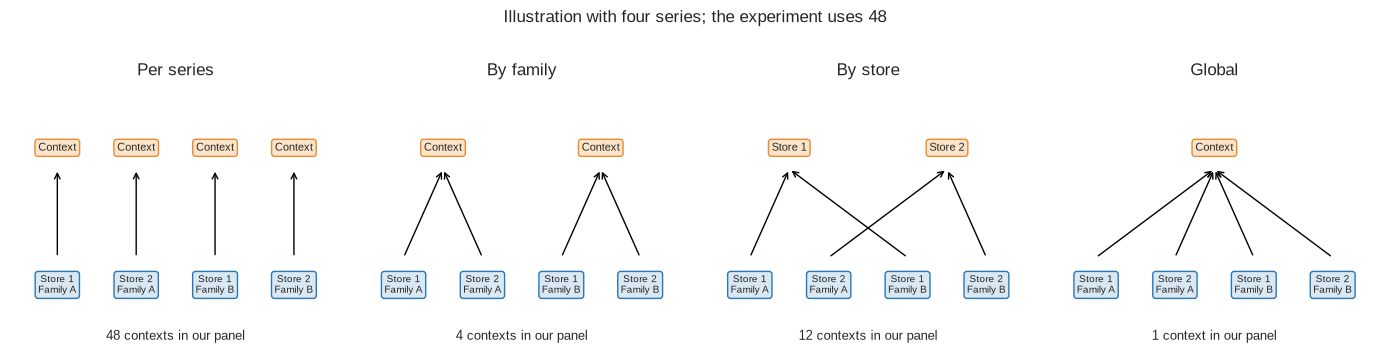

,date,series_id,family,store_nbr,onpromotion,week_sin_1,sales
789,2017-05-31,1 / BEVERAGES,BEVERAGES,1,31,-0.782,2554.000
14645,2017-05-31,2 / BEVERAGES,BEVERAGES,2,28,-0.782,2942.000
1655,2017-05-31,1 / BREAD/BAKERY,BREAD/BAKERY,1,5,-0.782,439.526
15511,2017-05-31,2 / BREAD/BAKERY,BREAD/BAKERY,2,6,-0.782,680.000


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, strategy in zip(axes, ["Per series", "By family", "By store", "Global"]):
    ax.set(xlim=(-.6, 3.6), ylim=(-.9, 3.5), title=strategy)
    for j, family in enumerate(["Family A", "Family B"]):
        for i in range(2):
            x = j * 2 + i
            ax.text(x, .2, f"Store {i+1}\n{family}", ha="center", va="center", fontsize=7,
                    bbox=dict(boxstyle="round", facecolor="#DAE8F4", edgecolor="#2878B5"))
            target_x = {"Per series": x, "By family": j * 2 + .5,
                        "By store": i * 2 + .5, "Global": 1.5}[strategy]
            ax.annotate("", xy=(target_x, 2.1), xytext=(x, .65), arrowprops=dict(arrowstyle="->"))
    context_x = range(4) if strategy == "Per series" else ([1.5] if strategy == "Global" else [.5, 2.5])
    for k, x in enumerate(context_x):
        label = f"Store {k+1}" if strategy == "By store" else "Context"
        ax.text(x, 2.4, label, ha="center", fontsize=8,
                bbox=dict(boxstyle="round", facecolor="#FBE4C9", edgecolor="#E88B32"))
    count = {"Per series": 48, "By family": 4, "By store": 12, "Global": 1}[strategy]
    ax.text(1.5, -.7, f"{count} context{'s' if count > 1 else ''} in our panel", ha="center", fontsize=9)
    ax.axis("off")
fig.suptitle("Illustration with four series; the experiment uses 48", y=1.02)
fig.tight_layout()
plt.show()

# Actual rows entering shared contexts: pool across stores OR across families.
display(features.loc[features.store_nbr.isin(["1", "2"]) & features.family.isin(FAMILIES[:2])
                     & features.date.eq(DEMO_ORIGIN),
                     ["date", "series_id", "family", "store_nbr", "onpromotion", "week_sin_1", "sales"]]
        .sort_values(["family", "store_nbr"]))


### How many fits?
Counts below are **per forecast origin**. “Fit” means one scikit-learn `fit` call that establishes a TabPFN context; it does not mean training the foundation model's weights. Each call may internally use an ensemble.

| Context strategy | Basic dates, no AR | Fourier, no AR | AR at a single lead | Direct AR, all $H$ leads |
|---|---:|---:|---:|---:|
| Per series | $S$ = **48** | $S$ = **48** | $S$ = **48** | $S H$ = **672** |
| By family | $G$ = **4** | $G$ = **4** | $G$ = **4** | $G H$ = **56** |
| By store | $L$ = **12** | $L$ = **12** | $L$ = **12** | $L H$ = **168** |
| Global | **1** | **1** | **1** | $H$ = **14** |

Here $S=48$ series, $G=4$ families, $L=12$ stores, and $H=14$. Across three test origins, each no-AR method needs **195 fits** across all pooling strategies; direct AR needs **2,730 fits**. The main comparison therefore needs **3,120 fits**. The $h=2$ results are reused from direct AR, not fitted again. The two-series walkthrough adds **32 fits**, plus one excluded warm-up.

## Evaluate three future windows
Use the origins June 30, July 14, and July 28, 2017. Each forecast covers the next 14 days without observing any sales inside that window. At the next origin, previously observed sales may enter history. Each backtest uses a fixed 730-day training window and keeps the forecast origin unchanged throughout the forecast window.

The primary score is **mean per-series seasonal MASE**: absolute forecast errors are divided by each series' training-only mean absolute seven-day difference, then averaged equally across series and origins. Zero-denominator series are reported and excluded from scaled scores for every method. We also report average within-series rank and the fraction of series won. Weekly seasonal-naive repeats the last observed week as a reference.


In [14]:
STRATEGIES = ["Per series", "By family", "By store", "Global"]
all_predictions, all_timings = [], []
for origin in TEST_ORIGINS:
    for strategy in ["Global", "By family", "By store", "Per series"]:
        for method, columns in [("Basic dates", IDENTIFIERS + KNOWN + BASIC),
                                ("Fourier", CALENDAR_COLUMNS)]:
            prediction, timing = calendar_forecast(features, origin, columns, strategy)
            all_predictions.append(prediction.assign(method=method))
            all_timings.append(timing.assign(method=method, horizon=0))
            print(f"{origin.date()} | {strategy} | {method}: {len(timing)} fits", flush=True)
        for h in range(1, H + 1):
            prediction, timing = direct_forecast(features, origin, h, strategy)
            all_predictions.append(prediction.assign(method="Direct AR"))
            all_timings.append(timing.assign(method="Direct AR", horizon=h))
        print(f"{origin.date()} | {strategy} | Direct AR: {H * len(timing)} fits", flush=True)

predictions = pd.concat(all_predictions, ignore_index=True)
timings = pd.concat(all_timings, ignore_index=True)
assert len(timings) == 3120
assert len(predictions) == 3 * 4 * 3 * 48 * H
assert not predictions.duplicated(["origin", "strategy", "method", "series_id", "horizon"]).any()
assert np.isfinite(predictions.prediction).all()


2017-06-30 | Global | Basic dates: 1 fits


2017-06-30 | Global | Fourier: 1 fits


2017-06-30 | Global | Direct AR: 14 fits


2017-06-30 | By family | Basic dates: 4 fits


2017-06-30 | By family | Fourier: 4 fits


...

2017-07-28 | By store | Fourier: 12 fits


2017-07-28 | By store | Direct AR: 168 fits


2017-07-28 | Per series | Basic dates: 48 fits


2017-07-28 | Per series | Fourier: 48 fits


2017-07-28 | Per series | Direct AR: 672 fits


In [15]:
scales = []
naive_parts = []
for origin in TEST_ORIGINS:
    train = wide_sales.loc[origin - pd.Timedelta(days=HISTORY_DAYS - 1):origin]
    scale = (train - train.shift(7)).abs().mean().rename("scale").reset_index()
    scales.append(scale.assign(origin=origin))
    query = features.loc[features.date.between(origin + pd.Timedelta(days=1), origin + pd.Timedelta(days=H))]
    reference = query[["series_id", "family", "date", "sales"]].copy()
    reference["horizon"] = (reference.date - origin).dt.days
    reference["prediction"] = [wide_sales.at[origin - pd.Timedelta(days=6) + pd.Timedelta(days=(h-1) % 7), series]
                               for h, series in zip(reference.horizon, reference.series_id)]
    naive_parts.append(reference.assign(origin=origin, strategy="Seasonal naive", method="Seasonal naive"))

scale_table = pd.concat(scales, ignore_index=True)
invalid_scales = scale_table.loc[~np.isfinite(scale_table.scale) | scale_table.scale.le(0)]
print(f"Excluded zero/undefined seasonal scales: {len(invalid_scales)} series-origin pairs")
if len(invalid_scales):
    display(invalid_scales)
scored = pd.concat([predictions, *naive_parts], ignore_index=True).merge(
    scale_table, on=["series_id", "origin"], validate="many_to_one")
scored["scaled_error"] = abs(scored.sales - scored.prediction) / scored.scale.where(scored.scale.gt(0))
assert np.isfinite(scored.prediction).all()

per_series = scored.groupby(["method", "strategy", "series_id"]).scaled_error.mean().reset_index()
per_series["rank"] = per_series.groupby("series_id").scaled_error.rank(method="average")
accuracy = per_series.groupby(["method", "strategy"]).agg(
    MASE=("scaled_error", "mean"), mean_rank=("rank", "mean")).reset_index()
runtime = timings.groupby(["method", "strategy"]).agg(
    fits=("seconds", "size"), seconds=("seconds", "sum"), peak_gpu_gb=("peak_gpu_gb", "max"),
    max_context_rows=("train_rows", "max"), ensemble_members=("ensemble_members", "max")).reset_index()
leaderboard = accuracy.merge(runtime, on=["method", "strategy"], how="left").sort_values("MASE")
display(leaderboard.round(3).fillna("—"))


Excluded zero/undefined seasonal scales: 0 series-origin pairs


,method,strategy,MASE,mean_rank,fits,seconds,peak_gpu_gb,max_context_rows,ensemble_members
6,Direct AR,Global,0.500,4.938,42.0,1254.55,5.587,32256.0,8.0
8,Fourier,By family,0.503,5.042,12.0,65.718,4.02,8736.0,8.0
4,Direct AR,By family,0.508,5.312,168.0,894.445,5.462,8064.0,8.0
0,Basic dates,By family,0.523,6.646,12.0,59.265,3.154,8736.0,8.0
5,Direct AR,By store,0.525,5.854,504.0,935.605,3.582,2688.0,8.0
7,Direct AR,Per series,0.530,5.479,2016.0,1593.882,1.544,672.0,8.0
11,Fourier,Per series,0.543,5.062,144.0,113.167,1.465,728.0,8.0
9,Fourier,By store,0.549,7.375,36.0,66.589,3.266,2912.0,8.0
3,Basic dates,Per series,0.555,6.708,144.0,104.585,1.281,728.0,8.0
10,Fourier,Global,0.557,7.979,3.0,97.436,5.227,34944.0,8.0


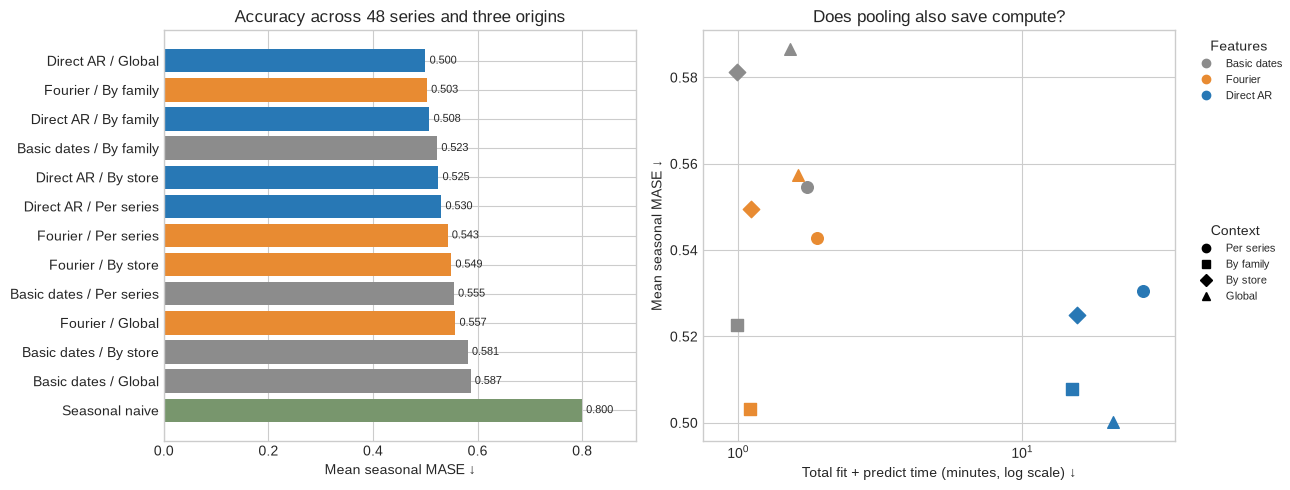

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = (leaderboard.method + " / " + leaderboard.strategy).where(
    leaderboard.method.ne("Seasonal naive"), "Seasonal naive")
bars = axes[0].barh(labels.iloc[::-1], leaderboard.MASE.iloc[::-1],
             color=[COLORS.get(x, "#78966D") for x in leaderboard.method.iloc[::-1]])
axes[0].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
axes[0].set_xlim(0, leaderboard.MASE.max() * 1.13)
axes[0].set(xlabel="Mean seasonal MASE ↓", title="Accuracy across 48 series and three origins")
markers = {"Per series": "o", "By family": "s", "By store": "D", "Global": "^"}
for row in leaderboard.dropna(subset=["seconds"]).itertuples():
    axes[1].scatter(row.seconds / 60, row.MASE, color=COLORS[row.method], marker=markers[row.strategy], s=70)
axes[1].set(xlabel="Total fit + predict time (minutes, log scale) ↓", ylabel="Mean seasonal MASE ↓",
            xscale="log", title="Does pooling also save compute?")
axes[1].set_xlim(0.75, leaderboard.seconds.max() / 60 * 1.3)
from matplotlib.lines import Line2D
feature_handles = [Line2D([], [], color=color, marker="o", linestyle="", label=method)
                   for method, color in COLORS.items()]
context_handles = [Line2D([], [], color="black", marker=marker, linestyle="", label=strategy)
                   for strategy, marker in markers.items()]
feature_legend = axes[1].legend(handles=feature_handles, title="Features", fontsize=8,
                               loc="upper left", bbox_to_anchor=(1.02, 1))
axes[1].add_artist(feature_legend)
axes[1].legend(handles=context_handles, title="Context", fontsize=8,
               loc="upper left", bbox_to_anchor=(1.02, .55))
fig.tight_layout()
plt.show()


### Compare pooling within each feature method
Average rank and win share below compare **only the four pooling strategies within each method**. First average errors over origins and horizons for each series, then rank. Tied wins share their weight, so the four win shares sum to 100%.


MASE  mean_rank  win_share
method      strategy                               
Basic dates By family   0.523      2.042      0.333
            Per series  0.555      1.979      0.396
            By store    0.581      2.812      0.146
            Global      0.587      3.167      0.125
Direct AR   Global      0.500      2.312      0.250
            By family   0.508      2.458      0.292
            By store    0.525      2.771      0.188
            Per series  0.530      2.458      0.271
Fourier     By family   0.503      2.042      0.375
            Per series  0.543      2.125      0.396
            By store    0.549      2.750      0.146
            Global      0.557      3.083      0.083

method          strategy      
Fourier         By family         0.519
Basic dates     By family         0.521
Direct AR       Global            0.545
Fourier         Per series        0.549
Direct AR       By family         0.564
                Per series        0.565
Basic dates     Per series        0.578
Fourier         By store          0.589
Basic dates     By store          0.609
                Global            0.616
Direct AR       By store          0.637
Fourier         Global            0.640
Seasonal naive  Seasonal naive    0.774
Name: MASE at t+2, dtype: float64

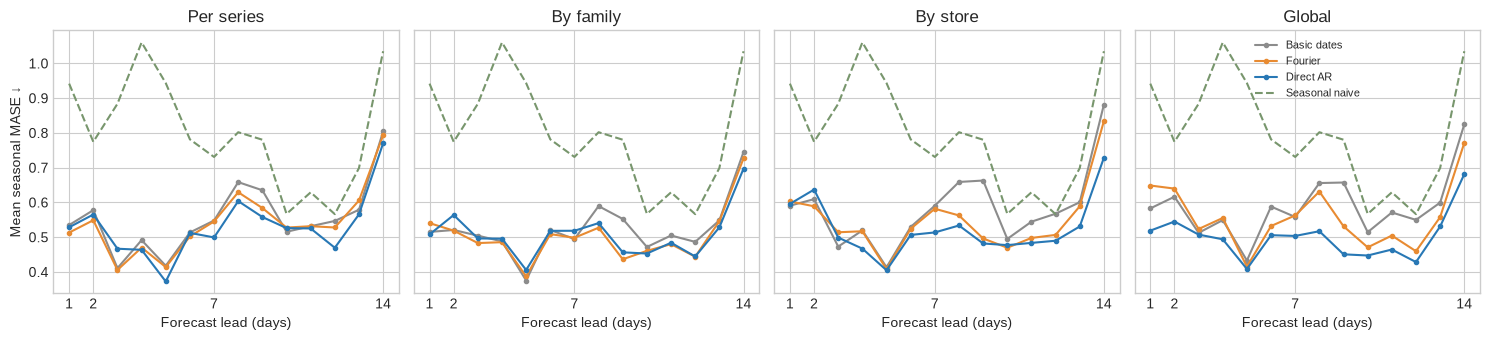

In [17]:
pooling = per_series.loc[per_series.method.ne("Seasonal naive")].copy()
pooling["pooling_rank"] = pooling.groupby(["method", "series_id"]).scaled_error.rank(method="average")
best = pooling.groupby(["method", "series_id"]).scaled_error.transform("min")
pooling["winner"] = pooling.scaled_error.eq(best).astype(float)
pooling["win_share"] = pooling.winner / pooling.groupby(["method", "series_id"]).winner.transform("sum")
pooling_summary = pooling.groupby(["method", "strategy"]).agg(
    MASE=("scaled_error", "mean"), mean_rank=("pooling_rank", "mean"), win_share=("win_share", "mean"))
display(pooling_summary.sort_values(["method", "MASE"]).round(3))

h2 = scored.loc[scored.horizon.eq(2)].groupby(["method", "strategy"]).scaled_error.mean()
display(h2.rename("MASE at t+2").sort_values().round(3))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, strategy in zip(axes, STRATEGIES):
    for method in COLORS:
        rows = scored.loc[scored.strategy.eq(strategy) & scored.method.eq(method)]
        curve = rows.groupby("horizon").scaled_error.mean()
        ax.plot(curve.index, curve, "o-", color=COLORS[method], label=method, markersize=3)
    naive_curve = scored.loc[scored.method.eq("Seasonal naive")].groupby("horizon").scaled_error.mean()
    ax.plot(naive_curve.index, naive_curve, "--", color="#78966D", label="Seasonal naive")
    ax.set(title=strategy, xlabel="Forecast lead (days)", xticks=[1, 2, 7, 14])
axes[0].set_ylabel("Mean seasonal MASE ↓")
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()


Global direct AR has the lowest test MASE and takes less model time than per-series direct AR. Fourier features improve mean test MASE across the pooling strategies. The illustrated series were selected on an earlier development window to show this improvement; the test comparison includes the full panel.

Family pooling is particularly useful for the Fourier model: its accuracy is close to global direct AR, with much less fit-and-predict time.

Store pooling also improves direct AR accuracy and reduces model time relative to per-series fits. Global pooling improves direct AR but hurts the non-autoregressive methods, so validate the feature representation and pooling level together.


## Apply the pattern to your own panel
Start with a long table containing a series identifier, a date, a target, and known covariates. Make the forecast origin explicit before building any target-derived feature. Use target-date calendar and planned covariates, and origin-date history.

A no-AR model can query many future dates from one context. A direct AR model uses one context per lead time. Pooling changes which related histories enter that context; whether family, store, or global pooling is preferable is a validation question.

This run used TabPFN **9.1.0**, the standard **3.5** model with **eight ensemble members**, and **one NVIDIA L4 with 16 allocated CPUs**. The library retained its default threading (eight PyTorch threads).

The timings here sum synchronized fit and prediction calls after a separate warm-up. They exclude download, feature preparation, plotting, and cleanup; GPU memory is peak allocated PyTorch memory, not whole-device utilization. Results describe this fixed subset, these origins, and this hardware. The date-feature examples and the pooled comparison do not establish that Fourier terms or global pooling always win.
